In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/Mall_Customers - Mall_Customers.csv')
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
from sklearn.cluster import KMeans
data=df[['Annual Income (k$)','Spending Score (1-100)']]
kmeans = KMeans(3)
kmeans.fit(data)
clusters = kmeans.predict(data)

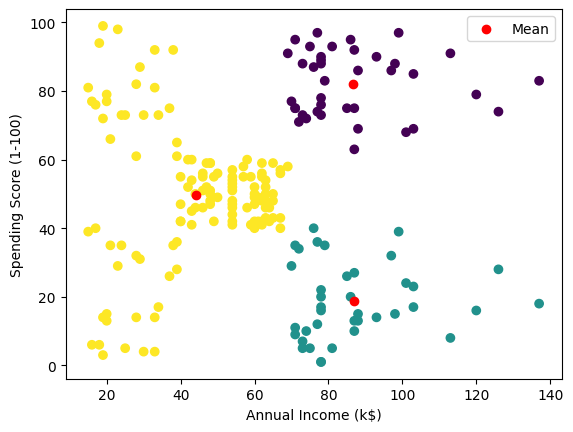

In [14]:
plt.scatter(df['Annual Income (k$)'],df['Spending Score (1-100)'],c=kmeans.labels_)
centers=kmeans.cluster_centers_
plt.scatter( centers[:,0],centers[:,1],c = 'red',label='Mean')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()


In [22]:
wcss=[]
for i in range(1,11):
  model = KMeans(i)
  model.fit(data)
  cluster =  model.predict(data)
  wcss.append(model.inertia_)

print(wcss)

[269981.28000000014, 184609.98434090626, 106348.37306211119, 73679.78903948837, 44448.45544793369, 38797.9027638142, 30259.657207285458, 26086.45161466887, 23083.56515395632, 20271.40337782372]


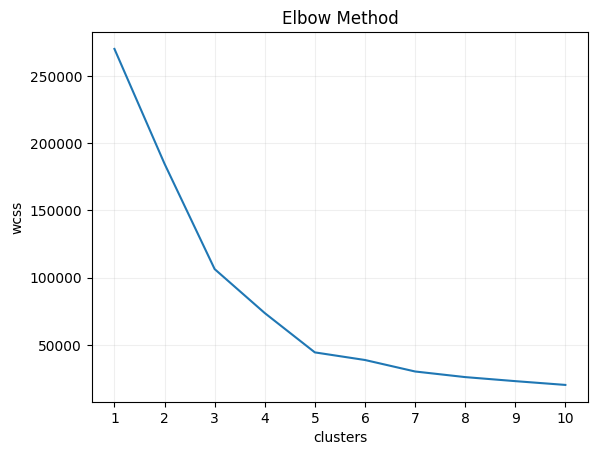

In [30]:
plt.plot(range(1,11),wcss)
plt.xlabel('clusters')
plt.ylabel('wcss')
plt.title('Elbow Method')
plt.grid(alpha=0.2)
plt.xticks(range(1,11))
plt.show()

Text(0, 0.5, 'Spending Score (1-100)')

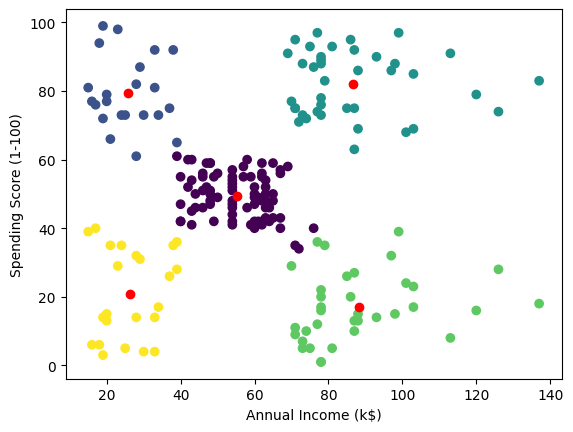

In [36]:
model2 = KMeans(5)
model2.fit(data)
clusters2= model2.predict(data)
plt.scatter(df['Annual Income (k$)'],df['Spending Score (1-100)'],c=model2.labels_)
centers2=model2.cluster_centers_
plt.scatter(centers2[:,0],centers2[:,1],c='red')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')


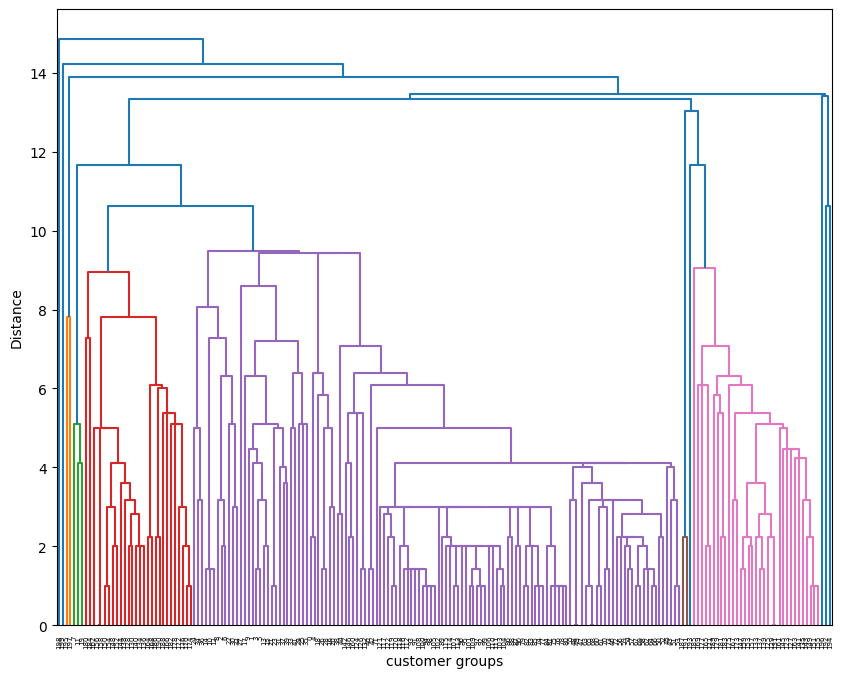

In [42]:
from scipy.cluster.hierarchy import linkage,dendrogram

z = linkage(data)
plt.figure(figsize=(10,8))
dendrogram(z)
plt.xlabel('customer groups')
plt.ylabel('Distance')
plt.show()

In [43]:
income = float(input("enter the annual income  (k$)"))
spending = float(input("enter the spending score (1-100)"))
user_data = pd.DataFrame([[income,spending]],columns=['Annual Income (k$)','Spending Score (1-100)'])
result= model2.predict(user_data)
print('cluster numbets',result)

enter the annual income  (k$)20
enter the spending score (1-100)40
cluster numbets [4]
